# Monte Carlo Pricing & Greeks Engine

A presentation of the completed Python research library, v0.17.0.
The code below calls library functions and reads published experiments;
no essential pricing method is implemented here.

Run from the repository root or `notebooks/` after installing the package and
research dependencies. Saved outputs were produced by sequential Python execution
of these ordinary cells, not by a Jupyter kernel. Single seeded demos are
illustrations; statistical conclusions use the independently replicated studies.


In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from mc_pricer import (
    BlackScholesModel, EuropeanOption, ArithmeticAsianOption, HestonModel,
    black_scholes_price, make_rng, price_monte_carlo, price_heston_monte_carlo,
)
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/mc_pricer").is_dir())
RESULTS = ROOT / "results"
print("Loaded pricing library; evidence is read from the repository's results directory.")


Loaded pricing library; evidence is read from the repository's results directory.


## 1. Price as a risk-neutral expectation

$$V_0=e^{-rT}\mathbb E^{\mathbb Q}[\Phi(S)],\qquad
\widehat V_N=\frac1N\sum_{i=1}^N e^{-rT}\Phi_i.$$

GBM grid transitions are exact. For a European payoff, simulate only the terminal
value. The library computes the mean and SE from discounted independent samples.
The following single run is compared with an independent analytical target;
one interval containing the target is not a coverage study.


In [2]:
model = BlackScholesModel(100.0, 0.05, 0.20)
call = EuropeanOption(100.0)
quote = price_monte_carlo(model, call, 1.0, 100_000, rng=make_rng(17))
print(f"Call MC: {quote.price:.6f}; SE: {quote.standard_error:.6f}")
print(f"Sampling interval: {quote.confidence_interval}")
print(f"Analytical target: {black_scholes_price(model, 100.0, 1.0):.6f}")


Call MC: 10.448581; SE: 0.046720
Sampling interval: (10.357012094209626, 10.540149300064705)
Analytical target: 10.450584


## 2. Measure convergence across independent replications

The M5 study has 200 independent runs at each sample count. Theory predicts
SE proportional to $N^{-1/2}$ when discounted payoffs have finite variance.
Realized absolute error need not decrease monotonically. The reported slopes
are descriptive fits, while the underlying statement comes from variance algebra.


product  n_replications  log_mean_se_slope  log_rmse_slope
   call             200          -0.499848       -0.511481
    put             200          -0.500322       -0.497817


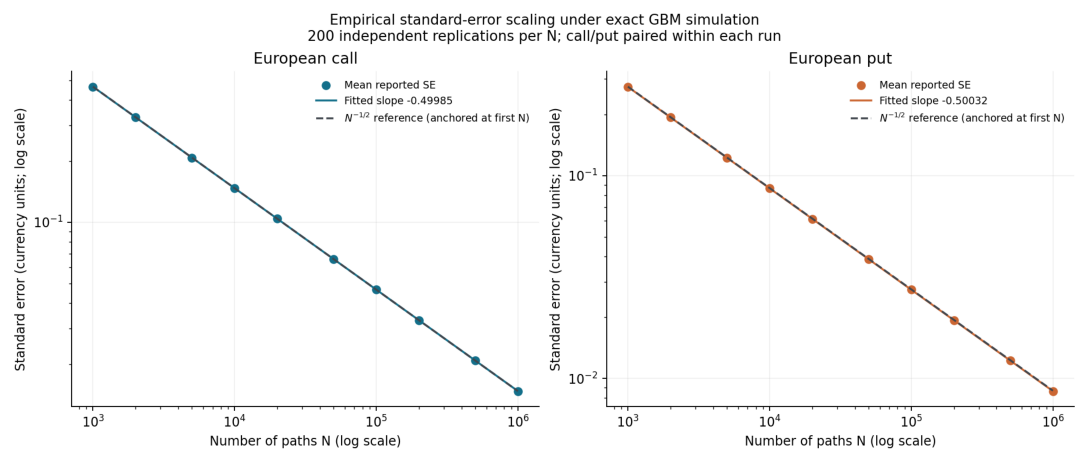

In [3]:
slopes = pd.read_csv(RESULTS / "tables/mc_convergence_slopes.csv")
print(slopes[["product", "n_replications", "log_mean_se_slope", "log_rmse_slope"]].to_string(index=False))
figure = plt.imread(RESULTS / "figures/mc_loglog_convergence.png")
plt.figure(figsize=(10, 5))
plt.imshow(figure)
plt.axis("off")
plt.tight_layout()
plt.show()


## 3. A control with a known expectation

$$X_{cv}=X-\widehat\beta(Y-\mathbb EY),\qquad
\beta^*=\frac{\operatorname{Cov}(X,Y)}{\operatorname{Var}(Y)}.$$

The arithmetic Asian uses a geometric Asian on the same twelve dates as its
control. An independent pilot fits beta. The 12,000-path budget below includes
1,200 pilot paths, leaving 10,800 production samples. Two payoff functions are
evaluated per path. The final comparison uses 50 independent runs per method;
it is different from the earlier 200-run, 10,000-path M10 study.


In [4]:
asian = price_monte_carlo(
    model, ArithmeticAsianOption(100.0), 1.0, 12_000, n_steps=12,
    variance_reduction="control_variate", n_pilot_paths=1_200, rng=make_rng(18),
)
print(f"Illustrative Asian quote: {asian.price:.6f}; SE: {asian.standard_error:.6f}")
print(f"Paths including pilot: {asian.n_paths}; independent production rows: {asian.n_independent_samples}")
comparisons = pd.read_csv(RESULTS / "tables/final_comparisons.csv")
print(comparisons.loc[comparisons.case == "asian_call_12",
    ["reference", "candidate", "empirical_vrf", "bootstrap_lower", "bootstrap_upper"]].to_string(index=False))


Illustrative Asian quote: 6.152389; SE: 0.002278
Paths including pilot: 12000; independent production rows: 10800
reference       candidate  empirical_vrf  bootstrap_lower  bootstrap_upper
     none      antithetic       1.321265         0.744586         2.391895
     none control_variate     578.436502       300.137578      1123.212398


## 4. Greeks: preserve the right covariance and state the budget

Central FD Delta shares Gaussian shocks between spot bumps. Pathwise call Delta
uses $e^{-rT}\mathbf1_{S_T>K}S_T/S_0$. LR spot Delta weights the discounted payoff
by $Z/(S_0\sigma\sqrt T)$ and also supports digital payoffs.

The M16 Delta comparison spends 12,000 terminal valuations per run: 6,000 FD rows
or 12,000 PW/LR rows. Gamma and Vega use central differences; their units and
finite-bump bias differ. This table does not claim to implement Heston Greeks.


In [5]:
benchmark = pd.read_csv(RESULTS / "tables/final_benchmark.csv")
greeks = benchmark.loc[benchmark.quantity != "price"]
print(greeks[["quantity", "method", "n_paths", "n_payoff_evaluations",
              "mean_estimate", "analytical_value", "rmse"]].to_string(index=False))


quantity method  n_paths  n_payoff_evaluations  mean_estimate  analytical_value     rmse
   delta     fd     6000                 12000       0.636611          0.636831 0.008437
   delta     pw    12000                 12000       0.636853          0.636831 0.004831
   delta     lr    12000                 12000       0.640283          0.636831 0.011546
   gamma     fd     4000                 12000       0.018892          0.018762 0.001621
    vega     fd     6000                 12000      37.356527         37.524035 0.989065


## 5. Heston: sampling error is not integration bias

The Heston simulator carries raw auxiliary variance and uses its positive part
inside the coefficients. Stock uses old effective variance in an exponential
step. Fixing twelve contractual dates while refining integration steps isolates
time-integration effects from changing the exotic contract.

The JSON is an illustrative risk-neutral parameter handoff, not a fitted market
calibration. In the high-xi study, European error at twelve steps exceeds fourteen
sampling SEs; at 384 steps residual bias is unresolved by the observed SE.


In [6]:
heston = HestonModel.from_json(
    (ROOT / "examples/heston_calibration.json").read_text(), spot=100.0, rate=0.05,
)
heston_quote = price_heston_monte_carlo(
    heston, ArithmeticAsianOption(100.0), 1.0, 12_000, 384,
    n_observations=12, rng=make_rng(20),
)
print(f"Illustrative Heston Asian: {heston_quote.price:.6f}; sampling SE: {heston_quote.standard_error:.6f}")
heston_results = pd.read_csv(RESULTS / "tables/heston_convergence.csv")
selection = ((heston_results.scenario == "high_xi")
             & (heston_results["product"] == "european_call")
             & heston_results.n_steps.isin([12, 384]))
print(heston_results.loc[selection, ["n_steps", "mean_estimate", "reference_price",
                                    "estimated_bias", "pooled_standard_error"]].to_string(index=False))


Illustrative Heston Asian: 6.103889; sampling SE: 0.065859
 n_steps  mean_estimate  reference_price  estimated_bias  pooled_standard_error
      12       9.964268         9.531708        0.432561               0.029563
     384       9.542327         9.531708        0.010619               0.027320


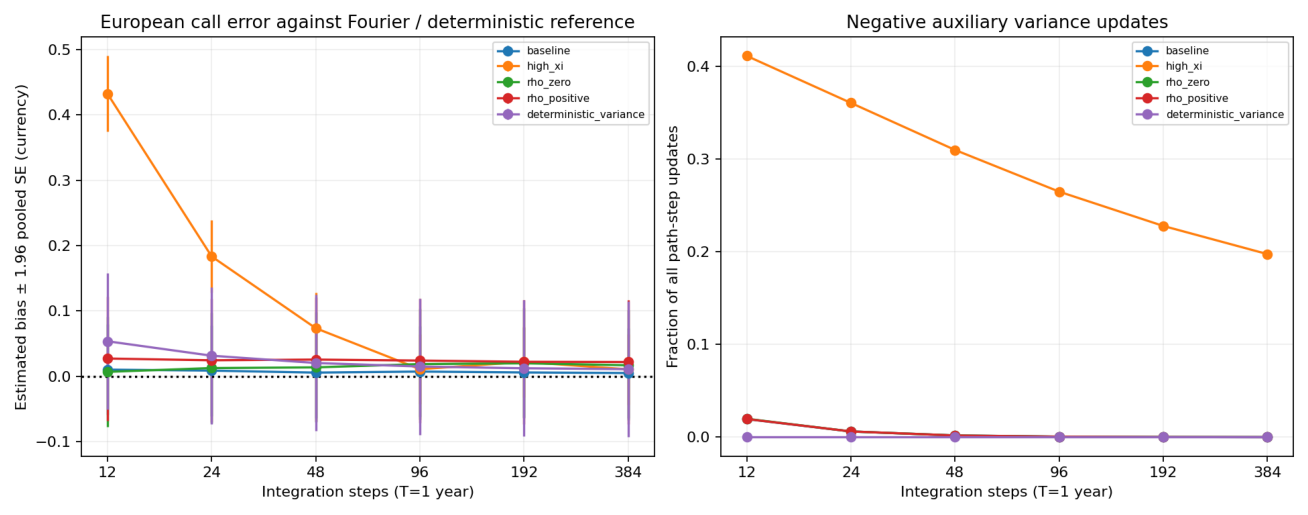

In [7]:
figure = plt.imread(RESULTS / "figures/heston_time_convergence.png")
plt.figure(figsize=(12, 5))
plt.imshow(figure)
plt.axis("off")
plt.tight_layout()
plt.show()


## 6. Keep failures visible

Antithetics can increase barrier variance. A rare event absent from all simulated
paths can generate zero SE without zero population risk. In M16, the LR Delta
repeated-mean interval misses its target at 2.193 empirical SEs; this is retained
and is not, by itself, proof of bias. Pointwise intervals do not supply simultaneous
coverage. Bootstrap cannot discover unobserved tails.


In [8]:
rare = pd.read_csv(RESULTS / "tables/robustness_rare_events.csv")
print(rare.loc[rare.scenario == "rare", ["exercise_probability", "pathwise_paths",
    "theoretical_no_active_probability", "observed_zero_se_rate"]].to_string(index=False))
window = pd.read_csv(RESULTS / "tables/antithetic_window_benchmark.csv")
print("Population plain/antithetic variance ratio in barrier counterexample:",
      round(float(window.population_vrf_quadrature.iloc[0]), 6))
index = pd.read_csv(RESULTS / "tables/final_evidence_index.csv")
assert len(index) == 12
metadata = json.loads((RESULTS / "raw/final_study.json").read_text())
for relative, expected_hash in metadata["output_sha256"].items():
    assert hashlib.sha256((RESULTS / relative).read_bytes()).hexdigest() == expected_hash
print("12 required figures indexed; all M16 output hashes verified.")


 exercise_probability  pathwise_paths  theoretical_no_active_probability  observed_zero_se_rate
             0.000011           20000                           0.797997                   0.84
Population plain/antithetic variance ratio in barrier counterexample: 0.771985
12 required figures indexed; all M16 output hashes verified.


## Continue the technical discussion

Read the [research report](../docs/results.md), [mathematical derivations](../docs/mathematical_background.md)
and [interview walkthrough](../docs/interview_walkthrough.md). Experiments can be
replayed individually using the evidence index, or the final comparison rebuilt
from saved raw rows without changing timings.

**Implemented scope:** Black–Scholes pricing/Greeks and variance reduction;
Heston pricing and calibration import. **Deferred:** Heston Greeks/controls,
continuous barrier corrections, general batching, lookbacks, QMC and acceleration.
The notebook is a presentation layer for the library and its evidence.
